# 12. Калібрована консервативна LSTM

**Етап 12 з 13** · NASA C-MAPSS FD001 · RUL prediction


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import copy, json, os, random, zipfile
import re
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

DATA_DIR = Path(os.environ.get('FD001_DIR', '/content/drive/MyDrive/predictive_maintenance'))
OUT_DIR = Path(os.environ.get('FD001_OUT', 'outputs'))
OUT_DIR.mkdir(parents=True, exist_ok=True)
SEED, WINDOW_SIZE, HIDDEN_SIZE = 42, 80, 64
QUANTILE, TARGET_COVERAGE = 0.20, 0.80
MAX_EPOCHS, PATIENCE = 60, 10
BATCH_SIZE, LEARNING_RATE, NUM_WORKERS = 128, 1e-3, 2
RUL_CAP_FOR_REPORT, BASELINE_CYCLES, DETECTOR_WINDOW = 125, 20, 10
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PIN_MEMORY = DEVICE.type == 'cuda'

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print('Device:', DEVICE, '| Data:', DATA_DIR, '| Output:', OUT_DIR.resolve())


Device: cuda | Data: /content/drive/MyDrive/predictive_maintenance | Output: /content/outputs


In [ ]:
# Optional MLflow model registry integration.
# In Colab set MLFLOW_TRACKING_URI in the environment (or leave it empty to skip logging).
MLFLOW_TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", "").strip()
MLFLOW_EXPERIMENT = os.environ.get(
    "MLFLOW_EXPERIMENT", "Predictive Maintenance - Conservative LSTM"
)


def _mlflow_metric_name(name):
    return re.sub(r"[^a-z0-9_]+", "_", name.lower()).strip("_")


def log_torch_model_to_mlflow(model, run_name, params, metrics, model_name="model"):
    """Log a complete PyTorch model plus reproducibility metadata; no-op when URI is empty."""
    if not MLFLOW_TRACKING_URI:
        print("MLflow skipped: set MLFLOW_TRACKING_URI to enable remote logging.")
        return None

    try:
        import mlflow
        import mlflow.pytorch
    except ImportError as exc:
        raise RuntimeError("Install MLflow first: %pip install -q mlflow") from exc

    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    mlflow.set_experiment(MLFLOW_EXPERIMENT)
    serializable_metrics = {
        _mlflow_metric_name(key): float(value)
        for key, value in metrics.items()
        if np.isscalar(value) and np.isfinite(value)
    }
    model_for_log = copy.deepcopy(model).cpu().eval()

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params(params)
        mlflow.log_metrics(serializable_metrics)
        mlflow.log_dict(
            {"features": list(FEATURE_COLUMNS)}, "reproducibility/feature_columns.json"
        )
        try:
            mlflow.pytorch.log_model(model_for_log, name=model_name)
        except TypeError:  # MLflow < 3
            mlflow.pytorch.log_model(model_for_log, artifact_path=model_name)
        print("MLflow run:", run.info.run_id)
        return run.info.run_id


## Data and three-way engine split

Спочатку 20% engines назавжди резервуються для calibration. Решта 80% діляться 80/20 на train/validation, тому  64/16/20.

In [3]:
COLUMNS = ['unit_id', 'cycle', 'setting_1', 'setting_2', 'setting_3'] + [f'sensor_{i}' for i in range(1, 22)]

def load_fd001(data_dir):
    paths = [data_dir / name for name in ('train_FD001.txt', 'test_FD001.txt', 'RUL_FD001.txt')]
    missing = [str(path) for path in paths if not path.exists()]
    if missing: raise FileNotFoundError('Missing FD001 files:\n' + '\n'.join(missing))
    train = pd.read_csv(paths[0], sep=r'\s+', header=None, names=COLUMNS)
    test = pd.read_csv(paths[1], sep=r'\s+', header=None, names=COLUMNS)
    rul = pd.read_csv(paths[2], sep=r'\s+', header=None)[0].to_numpy(float)
    train = train.sort_values(['unit_id', 'cycle']).reset_index(drop=True)
    test = test.sort_values(['unit_id', 'cycle']).reset_index(drop=True)
    train['RUL'] = train.groupby('unit_id')['cycle'].transform('max') - train['cycle']
    if len(rul) != test.unit_id.nunique(): raise ValueError('RUL count does not match test engines')
    return train, test, rul

train_full, test_full, y_test_true = load_fd001(DATA_DIR)
dev_cal_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, cal_idx = next(dev_cal_split.split(train_full, groups=train_full['unit_id']))
development_raw = train_full.iloc[dev_idx].copy()
calibration_raw = train_full.iloc[cal_idx].copy()
train_val_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED + 1)
train_idx, val_idx = next(train_val_split.split(development_raw, groups=development_raw['unit_id']))
train_raw = development_raw.iloc[train_idx].copy()
val_raw = development_raw.iloc[val_idx].copy()

for name, frame in [('Train', train_raw), ('Validation', val_raw), ('Calibration', calibration_raw), ('Development', development_raw), ('Official test', test_full)]:
    print(f'{name:13s}: {frame.shape}, engines={frame.unit_id.nunique()}')
split_sets = [set(x.unit_id.unique()) for x in (train_raw, val_raw, calibration_raw)]
assert not (split_sets[0] & split_sets[1] or split_sets[0] & split_sets[2] or split_sets[1] & split_sets[2])


Train        : (13273, 27), engines=64
Validation   : (3288, 27), engines=16
Calibration  : (4070, 27), engines=20
Development  : (16561, 27), engines=80
Official test: (13096, 26), engines=100


## Self-contained preprocessing

Directional degradation score, warmup flag і scaler відповідають попередньому notebook. На етапі model selection preprocessing fit-иться лише на 64 train engines.

In [4]:
BASE_FEATURES = ['cycle', 'setting_1', 'setting_2', 'setting_3'] + [f'sensor_{i}' for i in range(1, 22)]
DIRECTIONS = {'sensor_4': 1, 'sensor_7': -1, 'sensor_11': 1, 'sensor_12': -1, 'sensor_15': 1, 'sensor_20': -1, 'sensor_21': -1}
FEATURE_COLUMNS = BASE_FEATURES + ['degradation_score', 'degradation_warmup']

class DegradationScore:
    def __init__(self, baseline_cycles=20, window=10, directions=None):
        self.baseline_cycles, self.window = baseline_cycles, window
        self.directions = directions or DIRECTIONS
        self.sensors = list(self.directions)
        self.direction = pd.Series(self.directions, dtype=float)
        self.scale_ = None
    def fit(self, df):
        residuals = []
        for _, engine in df.sort_values('cycle').groupby('unit_id', sort=False):
            calibration = engine[self.sensors].iloc[:self.baseline_cycles]
            residuals.append(calibration - calibration.median())
        residuals = pd.concat(residuals, ignore_index=True)
        self.scale_ = residuals.abs().median().mul(1.4826).clip(lower=1e-6)
        return self
    def transform(self, df):
        result = pd.Series(np.nan, index=df.index, dtype=float)
        for _, engine in df.groupby('unit_id', sort=False):
            engine = engine.sort_values('cycle')
            baseline = engine[self.sensors].iloc[:self.baseline_cycles].median()
            deviation = engine[self.sensors].sub(baseline).div(self.scale_)
            score = deviation.mul(self.direction).clip(lower=0).mean(axis=1).rolling(self.window, min_periods=1).mean()
            score.iloc[:self.baseline_cycles] = np.nan
            result.loc[engine.index] = score.to_numpy()
        return result
    def to_dict(self):
        return {'baseline_cycles': self.baseline_cycles, 'window': self.window, 'directions': self.directions, 'scale': {k: float(v) for k, v in self.scale_.items()}}

def add_features(df, detector):
    result = df.copy()
    result['degradation_score'] = detector.transform(result)
    result['degradation_warmup'] = result['degradation_score'].isna().astype('float32')
    return result

def fit_preprocessor(df):
    detector = DegradationScore(BASELINE_CYCLES, DETECTOR_WINDOW).fit(df)
    featured = add_features(df, detector)
    scaler = StandardScaler().fit(featured[FEATURE_COLUMNS].fillna(0).to_numpy(np.float64))
    return detector, scaler

def transform_data(df, detector, scaler):
    result = add_features(df, detector)
    result[FEATURE_COLUMNS] = scaler.transform(result[FEATURE_COLUMNS].fillna(0).to_numpy(np.float64))
    return result

detector_split, scaler_split = fit_preprocessor(train_raw)
train_scaled = transform_data(train_raw, detector_split, scaler_split)
val_scaled = transform_data(val_raw, detector_split, scaler_split)
print('Input features:', len(FEATURE_COLUMNS))


Input features: 27


## Partial histories, LSTM and training helpers

In [5]:
class PartialHistoryDataset(Dataset):
    def __init__(self, df, window_size=80):
        self.window_size, self.engines, self.index = window_size, [], []
        for _, engine in df.groupby('unit_id', sort=True):
            engine = engine.sort_values('cycle'); i = len(self.engines)
            self.engines.append((engine[FEATURE_COLUMNS].to_numpy(np.float32), engine['RUL'].to_numpy(np.float32)))
            self.index.extend((i, end) for end in range(1, len(engine) + 1))
    def __len__(self): return len(self.index)
    def __getitem__(self, item):
        i, end = self.index[item]; features, targets = self.engines[i]
        window = features[max(0, end - self.window_size):end]
        if len(window) < self.window_size:
            window = np.vstack([np.repeat(window[:1], self.window_size - len(window), axis=0), window])
        return torch.from_numpy(window.copy()), torch.tensor(targets[end - 1])

def make_loader(dataset, shuffle, seed=SEED):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0, generator=torch.Generator().manual_seed(seed))

def make_last_windows(df):
    ids, windows = [], []
    for unit_id, engine in df.groupby('unit_id', sort=True):
        features = engine.sort_values('cycle')[FEATURE_COLUMNS].to_numpy(np.float32)
        if len(features) < WINDOW_SIZE:
            features = np.vstack([np.repeat(features[:1], WINDOW_SIZE - len(features), axis=0), features])
        ids.append(int(unit_id)); windows.append(features[-WINDOW_SIZE:])
    return np.asarray(ids), np.asarray(windows, np.float32)

class RULLSTM(nn.Module):
    def __init__(self, in_features, hidden_size=64):
        super().__init__(); self.lstm = nn.LSTM(in_features, hidden_size, batch_first=True); self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        _, (hidden, _) = self.lstm(x); return self.fc(hidden[-1]).squeeze(-1)

class QuantileLoss(nn.Module):
    def __init__(self, q): super().__init__(); self.q = q
    def forward(self, prediction, target):
        error = target - prediction; return torch.maximum(self.q * error, (self.q - 1) * error).mean()

def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None; model.train(training); total = count = 0
    with (torch.enable_grad() if training else torch.inference_mode()):
        for X, y in loader:
            X, y = X.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            loss = loss_fn(model(X), y)
            if training:
                optimizer.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5); optimizer.step()
            total += loss.item() * len(X); count += len(X)
    return total / count

def predict_dataset(model, dataset):
    loader = make_loader(dataset, shuffle=False); predictions, targets = [], []
    model.eval()
    with torch.inference_mode():
        for X, y in loader:
            predictions.append(model(X.to(DEVICE, non_blocking=True)).cpu().numpy()); targets.append(y.numpy())
    return np.concatenate(predictions), np.concatenate(targets)


## Model selection on 64/16 engines

Epoch 001 | train=20.7878 | val=18.9113 | best=18.9113
Epoch 002 | train=18.8713 | val=17.4419 | best=17.4419
Epoch 003 | train=17.5115 | val=16.1742 | best=16.1742
Epoch 004 | train=16.3377 | val=15.0718 | best=15.0718
Epoch 005 | train=15.2924 | val=14.0818 | best=14.0818
Epoch 006 | train=14.3577 | val=13.2059 | best=13.2059
Epoch 007 | train=13.5262 | val=12.4622 | best=12.4622
Epoch 008 | train=12.8077 | val=11.8520 | best=11.8520
Epoch 009 | train=12.1123 | val=11.1821 | best=11.1821
Epoch 010 | train=11.4985 | val=10.6029 | best=10.6029
Epoch 011 | train=10.9402 | val=10.2086 | best=10.2086
Epoch 012 | train=10.4526 | val=9.5943 | best=9.5943
Epoch 013 | train=10.0140 | val=9.2290 | best=9.2290
Epoch 014 | train=9.6980 | val=9.0218 | best=9.0218
Epoch 015 | train=9.3934 | val=8.6936 | best=8.6936
Epoch 016 | train=9.0933 | val=8.4833 | best=8.4833
Epoch 017 | train=8.8152 | val=8.1714 | best=8.1714
Epoch 018 | train=8.5938 | val=8.0786 | best=8.0786
Epoch 019 | train=8.3615 | va

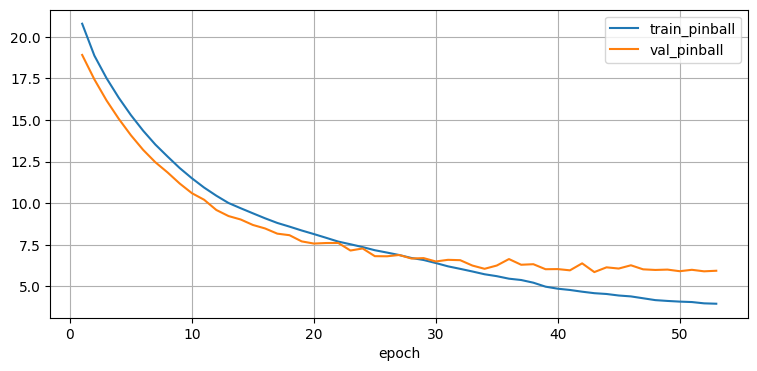

In [6]:
train_dataset, val_dataset = PartialHistoryDataset(train_scaled, WINDOW_SIZE), PartialHistoryDataset(val_scaled, WINDOW_SIZE)
train_loader, val_loader = make_loader(train_dataset, True), make_loader(val_dataset, False)
set_seed(); model = RULLSTM(len(FEATURE_COLUMNS), HIDDEN_SIZE).to(DEVICE); loss_fn = QuantileLoss(QUANTILE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=.5, patience=3, min_lr=1e-5)
best_state, best_loss, best_epoch, stale, history = None, float('inf'), 0, 0, []
for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, loss_fn, optimizer); val_loss = run_epoch(model, val_loader, loss_fn); scheduler.step(val_loss)
    history.append({'epoch': epoch, 'train_pinball': train_loss, 'val_pinball': val_loss})
    if val_loss < best_loss - 1e-4:
        best_state, best_loss, best_epoch, stale = copy.deepcopy(model.state_dict()), val_loss, epoch, 0
    else: stale += 1
    print(f'Epoch {epoch:03d} | train={train_loss:.4f} | val={val_loss:.4f} | best={best_loss:.4f}')
    if stale >= PATIENCE: print('Early stopping. Best epoch:', best_epoch); break
history_df = pd.DataFrame(history)
history_df.plot(x='epoch', y=['train_pinball', 'val_pinball'], figsize=(9,4), grid=True); plt.show()


## Refit on 80 development engines, then calibrate on untouched 20 engines

In [7]:
detector_final, scaler_final = fit_preprocessor(development_raw)
development_scaled = transform_data(development_raw, detector_final, scaler_final)
calibration_scaled = transform_data(calibration_raw, detector_final, scaler_final)
development_dataset = PartialHistoryDataset(development_scaled, WINDOW_SIZE)
calibration_dataset = PartialHistoryDataset(calibration_scaled, WINDOW_SIZE)
development_loader = make_loader(development_dataset, True)
set_seed(); final_model = RULLSTM(len(FEATURE_COLUMNS), HIDDEN_SIZE).to(DEVICE)
final_optimizer = torch.optim.AdamW(final_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
for epoch in range(1, best_epoch + 1):
    loss = run_epoch(final_model, development_loader, loss_fn, final_optimizer)
    print(f'Refit {epoch:03d}/{best_epoch:03d} | pinball={loss:.4f}')

cal_pred, cal_true = predict_dataset(final_model, calibration_dataset)
cal_error = cal_pred - cal_true
n_cal = len(cal_error)
finite_sample_level = min(1.0, np.ceil((n_cal + 1) * TARGET_COVERAGE) / n_cal)
safety_margin = max(0.0, float(np.quantile(cal_error, finite_sample_level, method='higher')))
cal_safe = np.clip(cal_pred - safety_margin, 0, None)
print('Calibration samples:', n_cal)
print('Finite-sample quantile level:', finite_sample_level)
print('Safety margin:', safety_margin)
print('Coverage before:', float(np.mean(cal_pred <= cal_true)))
print('Coverage after:', float(np.mean(cal_safe <= cal_true)))

calibrated_model = copy.deepcopy(final_model)
with torch.no_grad(): calibrated_model.fc.bias.sub_(safety_margin)
calibrated_model.eval()


Refit 001/043 | pinball=20.3731
Refit 002/043 | pinball=18.2202
Refit 003/043 | pinball=16.6601
Refit 004/043 | pinball=15.2807
Refit 005/043 | pinball=14.0826
Refit 006/043 | pinball=13.0398
Refit 007/043 | pinball=12.1584
Refit 008/043 | pinball=11.4454
Refit 009/043 | pinball=10.7953
Refit 010/043 | pinball=10.3069
Refit 011/043 | pinball=9.8557
Refit 012/043 | pinball=9.4716
Refit 013/043 | pinball=9.1438
Refit 014/043 | pinball=8.8227
Refit 015/043 | pinball=8.5685
Refit 016/043 | pinball=8.2947
Refit 017/043 | pinball=7.9487
Refit 018/043 | pinball=7.6702
Refit 019/043 | pinball=7.4475
Refit 020/043 | pinball=7.2052
Refit 021/043 | pinball=6.9800
Refit 022/043 | pinball=6.7814
Refit 023/043 | pinball=6.5762
Refit 024/043 | pinball=6.3787
Refit 025/043 | pinball=6.1505
Refit 026/043 | pinball=5.9787
Refit 027/043 | pinball=5.7901
Refit 028/043 | pinball=5.6691
Refit 029/043 | pinball=5.4736
Refit 030/043 | pinball=5.3500
Refit 031/043 | pinball=5.1844
Refit 032/043 | pinball=5.060

RULLSTM(
  (lstm): LSTM(27, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

## One-time official test evaluation

У таблиці одночасно показані retrained base P20 та calibrated P20. Для safety-моделі очікуємо coverage близько 0.80 і нижчий NASA Score.

,MAE,RMSE,R2,NASA Score,Overestimation rate,Mean overestimation,Max overestimation,Conservative coverage,Mean bias
Base P20 raw,11.676948,17.456274,0.823541,783.084274,0.30,16.077161,56.265808,0.70,-2.030652
Calibrated P20 raw,12.801345,17.880520,0.814860,703.642833,0.24,17.560980,53.924377,0.76,-4.372075
Base P20 capped,9.177269,14.092214,0.876334,360.756634,0.27,10.980800,48.000000,0.73,-3.247637
Calibrated P20 capped,10.536274,15.092033,0.858164,398.751565,0.22,12.095095,48.000000,0.78,-5.214432


Acceptance guide: coverage 0.75–0.85, overestimation 0.15–0.25, negative bias, NASA lower than base.


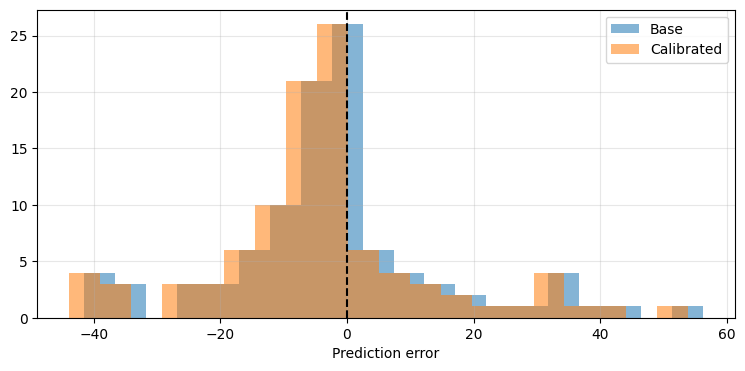

In [8]:
def nasa_score(y, p):
    e = np.asarray(p, float) - np.asarray(y, float); return float(np.sum(np.where(e < 0, np.exp(-e/13)-1, np.exp(e/10)-1)))
def evaluate(y, p, cap=None):
    y, p = np.asarray(y, float), np.asarray(p, float)
    if cap is not None: y, p = np.minimum(y, cap), np.minimum(p, cap)
    e = p-y; over = e>0
    return {'MAE': mean_absolute_error(y,p), 'RMSE': mean_squared_error(y,p)**.5, 'R2': r2_score(y,p), 'NASA Score': nasa_score(y,p), 'Overestimation rate': over.mean(), 'Mean overestimation': e[over].mean() if over.any() else 0., 'Max overestimation': e[over].max() if over.any() else 0., 'Conservative coverage': (e<=0).mean(), 'Mean bias': e.mean()}

test_scaled = transform_data(test_full, detector_final, scaler_final)
test_ids, X_test = make_last_windows(test_scaled)
assert np.array_equal(test_ids, np.arange(1, len(y_test_true)+1))
with torch.inference_mode(): base_pred = final_model(torch.from_numpy(X_test).to(DEVICE)).cpu().numpy()
base_pred = np.clip(base_pred, 0, None); safe_pred = np.clip(base_pred - safety_margin, 0, None)
rows = {}
for name, pred in [('Base P20 raw', base_pred), ('Calibrated P20 raw', safe_pred)]: rows[name] = evaluate(y_test_true, pred)
for name, pred in [('Base P20 capped', base_pred), ('Calibrated P20 capped', safe_pred)]: rows[name] = evaluate(y_test_true, pred, RUL_CAP_FOR_REPORT)
report = pd.DataFrame(rows).T
display(report)
print('Acceptance guide: coverage 0.75–0.85, overestimation 0.15–0.25, negative bias, NASA lower than base.')
fig, ax = plt.subplots(figsize=(9,4)); ax.hist(base_pred-y_test_true, bins=20, alpha=.55, label='Base'); ax.hist(safe_pred-y_test_true, bins=20, alpha=.55, label='Calibrated'); ax.axvline(0,color='black',ls='--'); ax.legend(); ax.set_xlabel('Prediction error'); ax.grid(alpha=.3); plt.show()


### Реєстрація фінальних моделей у MLflow

Цей крок виконується після одноразової оцінки, щоб у MLflow збереглися саме фінальні ваги, а не проміжна модель із model-selection.


In [ ]:
common_params = {
    "dataset": "NASA C-MAPSS FD001",
    "architecture": "RULLSTM",
    "quantile": QUANTILE,
    "window_size": WINDOW_SIZE,
    "hidden_size": HIDDEN_SIZE,
    "selected_epochs": best_epoch,
    "train_engines": 64,
    "validation_engines": 16,
    "calibration_engines": 20,
    "seed": SEED,
}

base_mlflow_run_id = log_torch_model_to_mlflow(
    model=final_model,
    run_name="FINAL | conservative_lstm_q20_retrained_base",
    params={**common_params, "calibrated": False},
    metrics={f"raw_{key}": value for key, value in rows["Base P20 raw"].items()},
    model_name="base_conservative_lstm_q20",
)

calibrated_mlflow_run_id = log_torch_model_to_mlflow(
    model=calibrated_model,
    run_name="FINAL | conservative_lstm_q20_calibrated",
    params={
        **common_params,
        "calibrated": True,
        "target_coverage": TARGET_COVERAGE,
        "safety_margin": safety_margin,
    },
    metrics={f"raw_{key}": value for key, value in rows["Calibrated P20 raw"].items()},
    model_name="calibrated_conservative_lstm_q20",
)


## Save separate base and calibrated artifacts

In [ ]:
BASE_MODEL_PATH = OUT_DIR / 'best_lstm_conservative_q20_retrained_base_w80.pt'
SAFE_MODEL_PATH = OUT_DIR / 'best_lstm_conservative_q20_calibrated_w80.pt'
SCALER_PATH = OUT_DIR / 'scaler_lstm_conservative_q20_calibrated_fd001.pkl'
DETECTOR_PATH = OUT_DIR / 'degradation_detector_conservative_q20_calibrated.json'
METADATA_PATH = OUT_DIR / 'conservative_q20_calibrated_metadata.json'
PREDICTIONS_PATH = OUT_DIR / 'conservative_q20_calibrated_fd001_predictions.csv'
HISTORY_PATH = OUT_DIR / 'conservative_q20_calibrated_training_history.csv'
ZIP_PATH = OUT_DIR / 'conservative_q20_calibrated_artifacts.zip'

def cpu_state(model): return {k: v.detach().cpu() for k,v in model.state_dict().items()}
torch.save(cpu_state(final_model), BASE_MODEL_PATH); torch.save(cpu_state(calibrated_model), SAFE_MODEL_PATH)
joblib.dump(scaler_final, SCALER_PATH)
DETECTOR_PATH.write_text(json.dumps(detector_final.to_dict(), indent=2), encoding='utf-8')
metadata = {'model_name': 'lstm_conservative_q20_calibrated', 'architecture': 'RULLSTM', 'quantile': QUANTILE, 'target_coverage': TARGET_COVERAGE, 'safety_margin': safety_margin, 'clip_min': 0.0, 'window_size': WINDOW_SIZE, 'input_size': len(FEATURE_COLUMNS), 'hidden_size': HIDDEN_SIZE, 'features': FEATURE_COLUMNS, 'train_engines': 64, 'validation_engines': 16, 'calibration_engines': 20, 'selected_epochs': best_epoch, 'seed': SEED, 'test_metrics': {name: {k: float(v) for k,v in values.items()} for name,values in rows.items()}}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
pd.DataFrame({'unit_id': test_ids, 'true_rul': y_test_true, 'base_q20': base_pred, 'calibrated_q20': safe_pred, 'base_error': base_pred-y_test_true, 'calibrated_error': safe_pred-y_test_true}).to_csv(PREDICTIONS_PATH, index=False)
history_df.to_csv(HISTORY_PATH, index=False)
artifacts = [BASE_MODEL_PATH, SAFE_MODEL_PATH, SCALER_PATH, DETECTOR_PATH, METADATA_PATH, PREDICTIONS_PATH, HISTORY_PATH]
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in artifacts: archive.write(path, arcname=path.name)
for path in artifacts + [ZIP_PATH]: print(path, f'({path.stat().st_size/1024:.1f} KiB)')
